# AWE v03 — compare 85 km and 15 km mapping

Extract the **entire ZIP**, open this notebook in that folder, and run from the top.
This version extends the Drive v02 actual-data notebook. It uses the same 49 Q20
orbit 4 observations, exact Epoch matches and reference Epoch (v02 frame 1179).
The missing v01 Epoch remains missing. Source indices are **1154–1202**;
930–979 are the old v01 selection labels, not v02 source indices.

**Why the roles can reverse:** in a fixed Earth-coordinate movie, mapping near
the cloud height reduces its satellite-induced parallax. The higher airglow
layer then drifts in the 15 km mapping. At 85 km, the airglow layer has less
parallax and clouds drift. Real winds, cloud-height variation, wave propagation
and changing brightness prevent either layer from being perfectly stationary.
The apparent speed is not a direct atmospheric wind measurement.

**Algorithm changes:** resample both geolocation solutions onto the same fixed
grid; re-estimate two velocity modes independently; do not reuse the 85 km
velocities or label “fast = cloud.” The alternating-median fitting equations
are retained. The optional joint model fits a map at each physical height to
the original observations once each, rather than averaging two decompositions.

The remapping changes coordinates, not native Radiance. An `imshow` of the native
arrays would look identical at both heights. These movies use geographic resampling.


In [2]:
# If needed, uncomment once, then restart the kernel:
# %pip install numpy scipy matplotlib netCDF4 pyproj ipython
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML
import dual_altitude as da

DATA_FOLDER = Path('.')
ITERATIONS = 64
REBUILD_PROJECTION = False
RUN_JOINT = True          # Experimental static two-height model
JOINT_ITERATIONS = 64
JOINT_PIXEL_STRIDE = 2    # Every second row/column of native observations
OUTPUT = DATA_FOLDER / f'dual_results_{ITERATIONS}'
OUTPUT.mkdir(exist_ok=True)
if REBUILD_PROJECTION or not (DATA_FOLDER/'dual_projected_frames.npz').exists():
    da.prepare(DATA_FOLDER)
d = np.load(DATA_FOLDER/'dual_projected_frames.npz')
I = {h: d[f'radiance{h}'].astype(float) for h in (85,15)}
lat, lon, frames = d['latitude'], d['longitude'], d['frame_index']
ref = int(d['reference_index'])
times = d['epoch'] - d['epoch'][ref]
assert np.all(np.diff(times)>0) and I[85].shape == I[15].shape
dx, dy = float(np.median(np.diff(lon))), float(np.median(np.diff(lat)))
extent = [lon[0]-dx/2, lon[-1]+dx/2, lat[0]-dy/2, lat[-1]+dy/2]
aspect = 1/np.cos(np.deg2rad(lat.mean()))
lo, hi = np.nanpercentile(np.concatenate([I[85].ravel(),I[15].ravel()]),[2,98])
print('Matched frames:',len(frames),'source indices:',frames[0],frames[-1])
print('Reference source frame:',frames[ref], 'elapsed span:',times[-1]-times[0],'seconds')
print('Common geographic pixels across both mappings and all frames:',d['common_coverage'].sum())


Projected 49 frames at 85 km
Projected 49 frames at 15 km
Matched frames: 49 source indices: 1154 1202
Reference source frame: 1179 elapsed span: 53.90625 seconds
Common geographic pixels across both mappings and all frames: 18799


## Synchronized geographic views
Both panels use identical timestamps, geographic limits and brightness scales.
Use the playback controls to watch the same features in both mappings. Blank
regions are missing samples or outside the footprint, not zero brightness.
The ROI is the v02 grid; only shared coverage is used for cross-altitude error comparisons.


In [4]:
fig, axes = plt.subplots(1,2,figsize=(11,5),layout='constrained')
images=[]
for ax,h in zip(axes,(85,15)):
    images.append(ax.imshow(I[h][ref],origin='lower',extent=extent,aspect=aspect,cmap='gray',vmin=lo,vmax=hi))
    ax.set(title=f'{h} km mapping',xlabel='Longitude (degrees E)',ylabel='Latitude (degrees N)')
fig.colorbar(images[0],ax=axes,label='kRayleigh',shrink=.7)
title=fig.suptitle('')
def update(j):
    for im,h in zip(images,(85,15)): im.set_data(I[h][j])
    title.set_text(f'v02 frame {frames[j]} | relative time {times[j]:+.2f} s')
    return images+[title]
animation=FuncAnimation(fig,update,frames=len(frames),interval=180,blit=False)
movie_html=animation.to_jshtml()
(OUTPUT/'altitude_comparison_movie.html').write_text(movie_html,encoding='utf-8')
plt.close(fig)
display(HTML(movie_html))


Once 
 
 Loop 
 
 Reflect

## Re-estimate motion separately
Patch NCC keeps multiple peaks per patch. The search radius now uses actual
elapsed seconds (including the Epoch gap), rather than a frame-count assumption.
Two separated peaks in velocity-density space are selected without the previous
0.18/0.22 pixels/s slow/fast class cuts. Components are ordered by apparent speed
only **within each mapping**. Inspect the scatter and support counts: two peaks
are a model assumption, not proof of two pure physical layers. A single constant
translation remains an approximation to the spatially varying parallax.


85 km: [lower speed, higher speed] velocities [east,north] pixels/s: [[-0.01200743 -0.02045714]
 [ 0.33442532 -0.46717782]] support: [252 232]
15 km: [lower speed, higher speed] velocities [east,north] pixels/s: [[-0.00884825 -0.01223101]
 [-0.44155293  0.5319613 ]] support: [293 329]


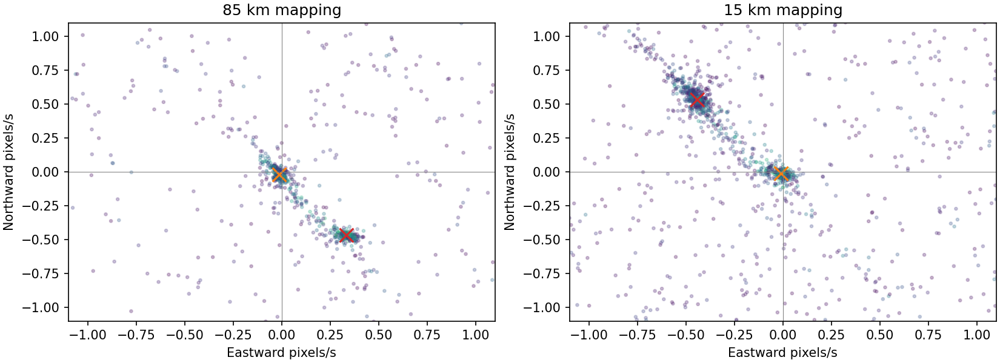

In [6]:
candidates, velocities = {}, {}
for h in (85,15):
    candidates[h]=da.motions(I[h],times)
    velocities[h],support=da.two_modes(candidates[h])
    np.savetxt(OUTPUT/f'motion_candidates_{h}km.csv',candidates[h],delimiter=',',
        header='x,y,start,end,vx_pixels_per_s,vy_pixels_per_s,ncc,rank',comments='')
    print(h,'km: [lower speed, higher speed] velocities [east,north] pixels/s:',velocities[h], 'support:',support)
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,h in zip(axes,(85,15)):
    a=candidates[h]
    ax.scatter(a[:,4],a[:,5],c=a[:,6],s=5,alpha=.25,vmin=.35,vmax=1)
    ax.scatter(*velocities[h].T,c=['tab:orange','tab:red'],s=120,marker='x')
    ax.axhline(0,color='gray',lw=.5); ax.axvline(0,color='gray',lw=.5)
    ax.set(title=f'{h} km mapping',xlabel='Eastward pixels/s',ylabel='Northward pixels/s',xlim=(-1.1,1.1),ylim=(-1.1,1.1))
fig.savefig(OUTPUT/'motion_comparison.png',dpi=150)
plt.show()


## Fit the same two-component model in each mapping
The alternating median updates and minimum support of 10 frames follow v02.
Unsupported updates retain previous template values. Higher-speed contrast has
median zero, so absolute brightness division remains undetermined. Each branch
has its own fixed training-evaluation mask. The next cell compares both on the
intersection of those masks and the geographic coverage at both heights.


85km, iteration 1: RMSE 0.46069
85km, iteration 2: RMSE 0.39372
85km, iteration 4: RMSE 0.32431
85km, iteration 8: RMSE 0.28268
85km, iteration 16: RMSE 0.26562
85km, iteration 32: RMSE 0.25879
85km, iteration 64: RMSE 0.25611
15km, iteration 1: RMSE 0.32495
15km, iteration 2: RMSE 0.29208
15km, iteration 4: RMSE 0.26918
15km, iteration 8: RMSE 0.25883
15km, iteration 16: RMSE 0.25504
15km, iteration 32: RMSE 0.25371
15km, iteration 64: RMSE 0.25306
{
  "85": {
    "velocities_pixels_per_s": [
      [
        -0.012007434693414285,
        -0.02045714179857028
      ],
      [
        0.33442532216864,
        -0.46717781791391927
      ]
    ],
    "shared_region_rmse_kR": 0.25611365289938004,
    "shared_pixels_per_frame": 18799,
    "iterations": 64
  },
  "15": {
    "velocities_pixels_per_s": [
      [
        -0.008848249604580596,
        -0.01223101447959832
      ],
      [
        -0.44155292651464195,
        0.5319612998727636
      ]
    ],
    "shared_region_rmse_kR": 0.2

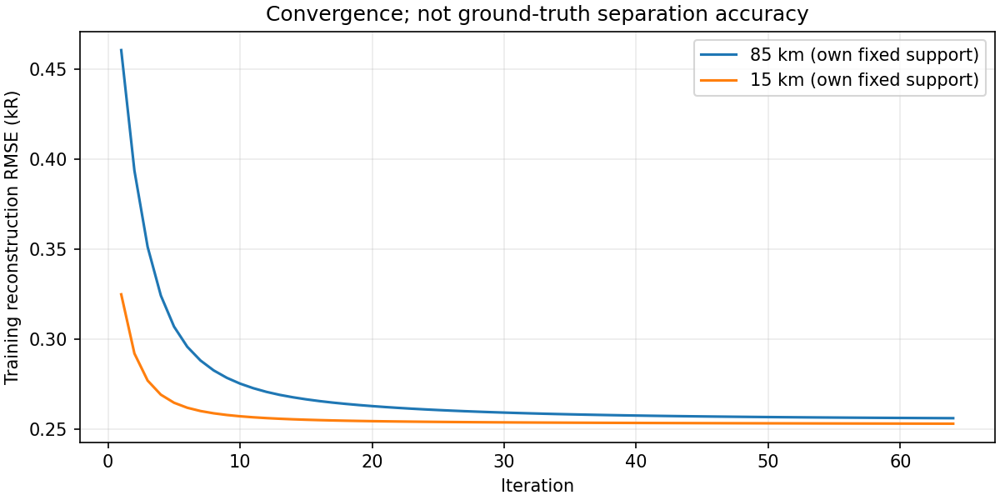

In [8]:
results={}
for h in (85,15):
    results[h]=da.separate(I[h],times,velocities[h],ITERATIONS,OUTPUT/f'{h}km')
common=d['common_coverage'] & results[85]['mask'] & results[15]['mask']
assert common.any(), 'No shared evaluation region'
summary={}
for h in (85,15):
    summary[str(h)]={'velocities_pixels_per_s':velocities[h].tolist(),
       'shared_region_rmse_kR':float(np.sqrt(np.mean(results[h]['residual'][:,common]**2))),
       'shared_pixels_per_frame':int(common.sum()),'iterations':ITERATIONS}
(OUTPUT/'comparison_metrics.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))
fig,ax=plt.subplots(figsize=(8,4),layout='constrained')
for h in (85,15): ax.plot(np.arange(1,ITERATIONS+1),results[h]['history'],label=f'{h} km (own fixed support)')
ax.set(xlabel='Iteration',ylabel='Training reconstruction RMSE (kR)',title='Convergence; not ground-truth separation accuracy')
ax.legend(); ax.grid(alpha=.25)
fig.savefig(OUTPUT/'convergence.png',dpi=150)
plt.show()


## Compare separated components at the same time
Change `FRAME_TO_VIEW` to any source index in `frames`. “Lower speed” can be an
airglow candidate at 85 km or a cloud candidate at 15 km, but identification
must also agree with morphology, motion and residuals. The two fits need not
be exact inverses. Identical color scales make disagreement visible.


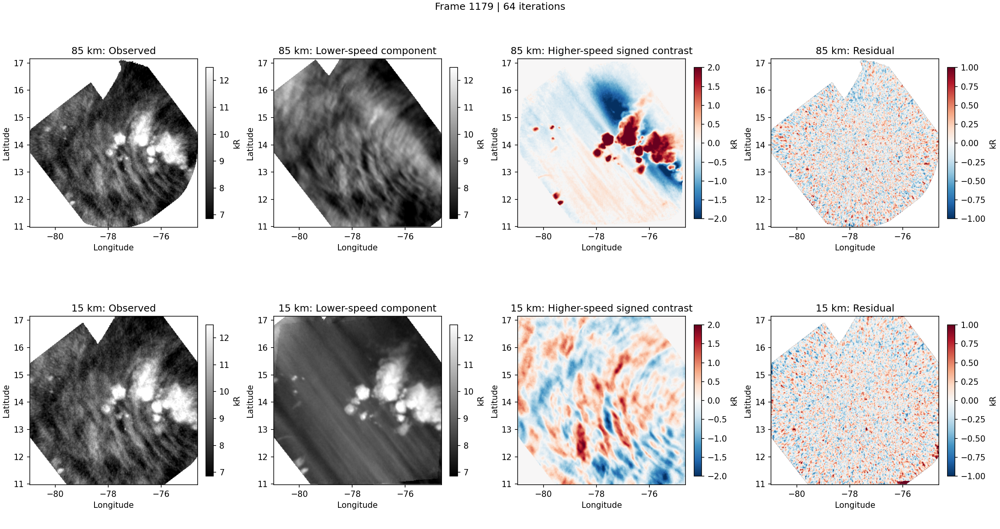

In [10]:
FRAME_TO_VIEW = 1179
j=int(np.flatnonzero(frames==FRAME_TO_VIEW)[0])
fig,axes=plt.subplots(2,4,figsize=(17,9),layout='constrained')
for row,h in enumerate((85,15)):
    r=results[h]
    slow=da.warp(r['slow'],r['velocities'][0],times[j])
    fast=da.warp(r['fast'],r['velocities'][1],times[j])
    arrays=[I[h][j],slow,fast,I[h][j]-slow-fast]
    for ax,a,title,cmap,limits in zip(axes[row],arrays,
            ['Observed','Lower-speed component','Higher-speed signed contrast','Residual'],
            ['gray','gray','RdBu_r','RdBu_r'],[(lo,hi),(lo,hi),(-2,2),(-1,1)]):
        im=ax.imshow(a,origin='lower',extent=extent,aspect=aspect,cmap=cmap,vmin=limits[0],vmax=limits[1])
        ax.set(title=f'{h} km: {title}',xlabel='Longitude',ylabel='Latitude')
        fig.colorbar(im,ax=ax,shrink=.6,label='kR')
fig.suptitle(f'Frame {frames[j]} | {ITERATIONS} iterations')
fig.savefig(OUTPUT/'separation_comparison.png',dpi=150)
plt.show()


## Optional: combine both heights in one physical-geometry model
This is an **experimental static-layer baseline**, not an average of the panels.
For each original radiance observation, predict

`I(t,p) = A85(latitude85(t,p), longitude85(t,p)) + C15(latitude15(t,p), longitude15(t,p))`.

Both maps use the geographic grid above, but each observation samples the appropriate
height coordinates. Bilinear sampling and its exact adjoint drive an LSMR fit;
first-difference regularization discourages unsupported roughness. The fit uses each
selected native observation once; the two remaps are not independent measurements.
The map mean is assigned to A85, leaving C15 as signed contrast. No-support pixels
are blank. Weakly supported pixels can be controlled by regularization.

This model assumes both layers are static over this short interval; it omits cloud
winds and evolving/propagating airglow. It can mix layers when geometry does not
constrain them. Training RMSE is not validation; use held-out times, synthetic
recovery and height/wind sensitivity before interpreting the maps physically.
LSMR stop code 7 means the iteration limit was reached, not convergence.
The native-space RMSE below is not directly comparable to the resampled-grid RMSE.


{
  "rmse": 0.2721810749870939,
  "stop_code": 7,
  "iterations": 64,
  "observations": 771316,
  "stride": 2,
  "smoothness": 0.3
}

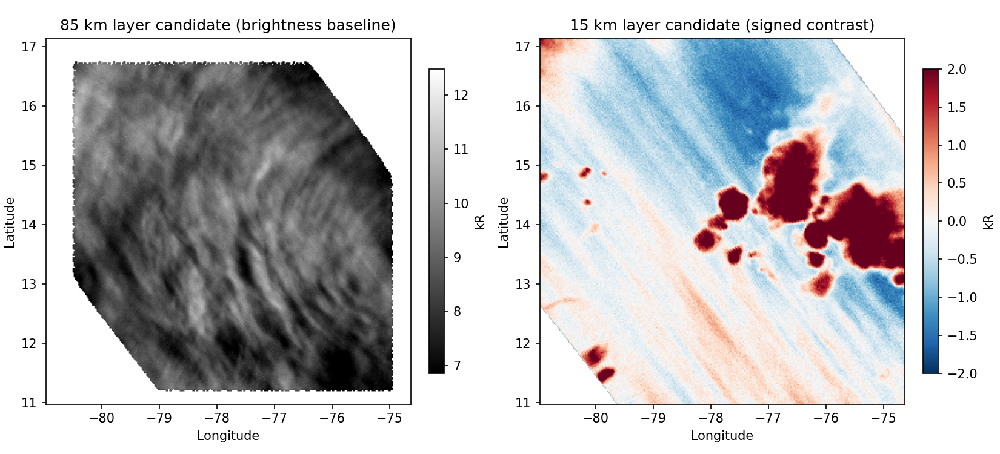

In [12]:
if RUN_JOINT:
    if not (DATA_FOLDER/'joint_geometry.npz').exists(): da.prepare(DATA_FOLDER)
    joint_maps,joint_metrics=da.joint_static(DATA_FOLDER,stride=JOINT_PIXEL_STRIDE,
                                          iterations=JOINT_ITERATIONS,smoothness=.3)
    (OUTPUT/'joint_metrics.json').write_text(json.dumps(joint_metrics,indent=2))
    print(joint_metrics)
    fig,axes=plt.subplots(1,2,figsize=(11,5),layout='constrained')
    for ax,a,title,cmap,limits in zip(axes,joint_maps,
            ['85 km layer candidate (brightness baseline)','15 km layer candidate (signed contrast)'],
            ['gray','RdBu_r'],[(lo,hi),(-2,2)]):
        im=ax.imshow(a,origin='lower',extent=extent,aspect=aspect,cmap=cmap,vmin=limits[0],vmax=limits[1])
        ax.set(title=title,xlabel='Longitude',ylabel='Latitude')
        fig.colorbar(im,ax=ax,shrink=.7,label='kR')
    fig.savefig(OUTPUT/'joint_layers.png',dpi=150)
    plt.show()


## Provenance and interpretation
- Input: `awe_l1r_q20_2023326T0542_00004_v02.nc`, nominal layer **85 km**.
- Exact matched subset and grid are retained from the Drive v02 bundle.
- The included `remap_altitude.py` is copied unchanged from the local awepy source;
  it intersects ISS lines of sight with WGS84 ellipsoid axes expanded by the target
  altitude. This is its shell approximation, not an exact constant-geodetic-height surface.
- `dual_altitude.py` contains the new projection, independent motion fits, and joint model.
- `AWE_v02_original_reference.ipynb` preserves the previous notebook for reference;
  run this v03 notebook for the self-contained dual-altitude workflow.
- The original full-orbit files and the Drive v02 upload are unchanged.
